In [3]:
import numpy as np
import pandas as pd

import matplotlib as plt
import seaborn as sns

%matplotlib inline

In [4]:
df=pd.read_csv('https://raw.githubusercontent.com/alexeygrigorev/mlbookcamp-code/master/chapter-03-churn-prediction/WA_Fn-UseC_-Telco-Customer-Churn.csv')

In [5]:
df.head().T

,0,1,2,3,4
customerID,7590-VHVEG,5575-GNVDE,3668-QPYBK,7795-CFOCW,9237-HQITU
gender,Female,Male,Male,Male,Female
SeniorCitizen,0,0,0,0,0
Partner,Yes,No,No,No,No
Dependents,No,No,No,No,No
tenure,1,34,2,45,2
PhoneService,No,Yes,Yes,No,Yes
MultipleLines,No phone service,No,No,No phone service,No
InternetService,DSL,DSL,DSL,DSL,Fiber optic
OnlineSecurity,No,Yes,Yes,Yes,No


In [6]:
df.columns=df.columns.str.lower().str.replace(' ', '_')
    

In [7]:
df.head().T

,0,1,2,3,4
customerid,7590-VHVEG,5575-GNVDE,3668-QPYBK,7795-CFOCW,9237-HQITU
gender,Female,Male,Male,Male,Female
seniorcitizen,0,0,0,0,0
partner,Yes,No,No,No,No
dependents,No,No,No,No,No
tenure,1,34,2,45,2
phoneservice,No,Yes,Yes,No,Yes
multiplelines,No phone service,No,No,No phone service,No
internetservice,DSL,DSL,DSL,DSL,Fiber optic
onlinesecurity,No,Yes,Yes,Yes,No


In [8]:
categorical_var=list(df.dtypes[df.dtypes=='str'].index)

In [9]:
for v in categorical_var:
    
    if v != 'totalcharges':
        df[v]=df[v].str.lower().str.replace(' ', '_')

In [10]:
df.head().T

,0,1,2,3,4
customerid,7590-vhveg,5575-gnvde,3668-qpybk,7795-cfocw,9237-hqitu
gender,female,male,male,male,female
seniorcitizen,0,0,0,0,0
partner,yes,no,no,no,no
dependents,no,no,no,no,no
tenure,1,34,2,45,2
phoneservice,no,yes,yes,no,yes
multiplelines,no_phone_service,no,no,no_phone_service,no
internetservice,dsl,dsl,dsl,dsl,fiber_optic
onlinesecurity,no,yes,yes,yes,no


In [11]:
df.dtypes

customerid              str
gender                  str
seniorcitizen         int64
partner                 str
dependents              str
tenure                int64
phoneservice            str
multiplelines           str
internetservice         str
onlinesecurity          str
onlinebackup            str
deviceprotection        str
techsupport             str
streamingtv             str
streamingmovies         str
contract                str
paperlessbilling        str
paymentmethod           str
monthlycharges      float64
totalcharges            str
churn                   str
dtype: object

In [12]:
df.totalcharges=pd.to_numeric(df.totalcharges, errors='coerce')

In [13]:
df.totalcharges = df.totalcharges.fillna(0)

In [14]:
df[df.totalcharges.notna()] [['gender','contract']]

,gender,contract
0,female,month-to-month
1,male,one_year
2,male,month-to-month
3,male,one_year
4,female,month-to-month
...,...,...
7038,male,one_year
7039,female,one_year
7040,female,month-to-month
7041,male,month-to-month


In [15]:
df.churn

0        no
1        no
2       yes
3        no
4       yes
       ... 
7038     no
7039     no
7040     no
7041    yes
7042     no
Name: churn, Length: 7043, dtype: str

In [16]:
df.churn=(df.churn=='yes').astype('int')

In [17]:
df.churn

0       0
1       0
2       1
3       0
4       1
       ..
7038    0
7039    0
7040    0
7041    1
7042    0
Name: churn, Length: 7043, dtype: int64

Train, test and spilit

In [18]:
n=len(df)

n_val= int(n*0.2)
n_test=int(n*0.2)
n_train= n - n_val - n_test

n, n_train, n_val, n_test

(7043, 4227, 1408, 1408)

In [19]:
np.random.seed(40)
idx= np.arange(n)

np.random.shuffle(idx)


df_train=df.iloc[idx[: n_train]]
df_val=df.iloc[idx[n_train : n_train+n_val]]
df_test=df.iloc[idx[n_train+n_val: ]]

In [20]:
df_train=df_train.reset_index(drop=True)
df_val=df_val.reset_index(drop=True)
df_test=df_test.reset_index(drop=True)

Train test spilit using sklearn

In [21]:
from sklearn.model_selection import train_test_split 

In [22]:
df_full_train, df_test= train_test_split(df,
                                         test_size=0.2,
                                         train_size=0.8,
                                         random_state=1)

In [23]:
df_train, df_val= train_test_split(df_full_train,
                                         test_size=0.25,
                                         train_size=0.75,
                                         random_state=1)

In [24]:
n, len(df_train), len(df_test), len(df_val)

(7043, 4225, 1409, 1409)

In [25]:
y_train =df_train['churn'].values
y_val =df_val['churn'].values
y_test =df_test['churn'].values

In [26]:
del df_train['churn']
del df_val['churn']
del df_test['churn']

In [27]:
df_train=df_train.reset_index(drop=True)
df_val=df_val.reset_index(drop=True)
df_test=df_test.reset_index(drop=True)

In [28]:
df_train

,customerid,gender,seniorcitizen,partner,dependents,tenure,phoneservice,multiplelines,internetservice,onlinesecurity,onlinebackup,deviceprotection,techsupport,streamingtv,streamingmovies,contract,paperlessbilling,paymentmethod,monthlycharges,totalcharges
0,8015-ihcgw,female,0,yes,yes,72,yes,yes,fiber_optic,yes,yes,yes,yes,yes,yes,two_year,yes,electronic_check,115.50,8425.15
1,1960-uycnn,male,0,no,no,10,yes,yes,fiber_optic,no,yes,yes,no,no,yes,month-to-month,yes,electronic_check,95.25,1021.55
2,9250-wypll,female,0,no,no,5,yes,yes,fiber_optic,no,no,no,no,no,no,month-to-month,no,electronic_check,75.55,413.65
3,6786-obwqr,female,0,yes,yes,5,yes,no,fiber_optic,no,no,no,no,yes,no,month-to-month,yes,electronic_check,80.85,356.10
4,1328-euzhc,female,0,yes,no,18,yes,no,no,no_internet_service,no_internet_service,no_internet_service,no_internet_service,no_internet_service,no_internet_service,two_year,no,mailed_check,20.10,370.50
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4220,1309-xgfsn,male,1,yes,yes,52,yes,yes,dsl,no,yes,yes,no,yes,yes,one_year,yes,electronic_check,80.85,4079.55
4221,4819-hjpiw,male,0,no,no,18,no,no_phone_service,dsl,no,no,no,no,no,no,month-to-month,no,mailed_check,25.15,476.80
4222,3703-vavcl,male,0,yes,yes,2,yes,no,fiber_optic,no,no,yes,yes,no,yes,month-to-month,no,credit_card_(automatic),90.00,190.05
4223,3812-lrzir,female,0,yes,yes,27,yes,yes,no,no_internet_service,no_internet_service,no_internet_service,no_internet_service,no_internet_service,no_internet_service,two_year,no,electronic_check,24.50,761.95


EDA

- Checking the missing values
- Target variable 
- Checking the the numerical and categorical variables

In [29]:
df_full_train=df_full_train.reset_index(drop=True)
df_full_train

,customerid,gender,seniorcitizen,partner,dependents,tenure,phoneservice,multiplelines,internetservice,onlinesecurity,...,deviceprotection,techsupport,streamingtv,streamingmovies,contract,paperlessbilling,paymentmethod,monthlycharges,totalcharges,churn
0,5442-pptjy,male,0,yes,yes,12,yes,no,no,no_internet_service,...,no_internet_service,no_internet_service,no_internet_service,no_internet_service,two_year,no,mailed_check,19.70,258.35,0
1,6261-rcvns,female,0,no,no,42,yes,no,dsl,yes,...,yes,yes,no,yes,one_year,no,credit_card_(automatic),73.90,3160.55,1
2,2176-osjuv,male,0,yes,no,71,yes,yes,dsl,yes,...,no,yes,no,no,two_year,no,bank_transfer_(automatic),65.15,4681.75,0
3,6161-erdgd,male,0,yes,yes,71,yes,yes,dsl,yes,...,yes,yes,yes,yes,one_year,no,electronic_check,85.45,6300.85,0
4,2364-ufrom,male,0,no,no,30,yes,no,dsl,yes,...,no,yes,yes,no,one_year,no,electronic_check,70.40,2044.75,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5629,0781-lkxbr,male,1,no,no,9,yes,yes,fiber_optic,no,...,yes,no,yes,yes,month-to-month,yes,electronic_check,100.50,918.60,1
5630,3507-gasnp,male,0,no,yes,60,yes,no,no,no_internet_service,...,no_internet_service,no_internet_service,no_internet_service,no_internet_service,two_year,no,mailed_check,19.95,1189.90,0
5631,8868-wozgu,male,0,no,no,28,yes,yes,fiber_optic,no,...,yes,no,yes,yes,month-to-month,yes,electronic_check,105.70,2979.50,1
5632,1251-krreg,male,0,no,no,2,yes,yes,dsl,no,...,no,no,no,no,month-to-month,yes,mailed_check,54.40,114.10,1


In [30]:
df_full_train.isnull().sum()

customerid          0
gender              0
seniorcitizen       0
partner             0
dependents          0
tenure              0
phoneservice        0
multiplelines       0
internetservice     0
onlinesecurity      0
onlinebackup        0
deviceprotection    0
techsupport         0
streamingtv         0
streamingmovies     0
contract            0
paperlessbilling    0
paymentmethod       0
monthlycharges      0
totalcharges        0
churn               0
dtype: int64

In [31]:
global_churn_rate=df_full_train.churn.mean()

In [32]:
round(global_churn_rate,3)

np.float64(0.27)

In [33]:
df_full_train.columns

Index(['customerid', 'gender', 'seniorcitizen', 'partner', 'dependents',
       'tenure', 'phoneservice', 'multiplelines', 'internetservice',
       'onlinesecurity', 'onlinebackup', 'deviceprotection', 'techsupport',
       'streamingtv', 'streamingmovies', 'contract', 'paperlessbilling',
       'paymentmethod', 'monthlycharges', 'totalcharges', 'churn'],
      dtype='str')

In [34]:
numerical_var=['tenure','monthlycharges','totalcharges']

In [35]:
categorical_var=['gender', 'seniorcitizen', 'partner', 'dependents',
       'phoneservice', 'multiplelines', 'internetservice',
       'onlinesecurity', 'onlinebackup', 'deviceprotection', 'techsupport',
       'streamingtv', 'streamingmovies', 'contract', 'paperlessbilling',
       'paymentmethod']

In [36]:
df_full_train[categorical_var].nunique()

gender              2
seniorcitizen       2
partner             2
dependents          2
phoneservice        2
multiplelines       3
internetservice     3
onlinesecurity      3
onlinebackup        3
deviceprotection    3
techsupport         3
streamingtv         3
streamingmovies     3
contract            3
paperlessbilling    2
paymentmethod       4
dtype: int64

Feature Importance: Churn Rate and risk ratio

- Identifying which features affect our target variable 

- 1 Churn Rate \
- 2 Risk Ratio \
- 2 Mutual Information

Churn Rate

In [37]:
churn_female=df_full_train[df_full_train.gender=='female'].churn.mean()
churn_male=df_full_train[df_full_train.gender=='male'].churn.mean()

churn_male, churn_female , global_churn_rate

(np.float64(0.2632135306553911),
 np.float64(0.27682403433476394),
 np.float64(0.26996805111821087))

In [38]:
round(global_churn_rate- churn_male, 4) , round(global_churn_rate- churn_female ,4)

(np.float64(0.0068), np.float64(-0.0069))

In [39]:
churn_yes_partner=df_full_train[df_full_train.partner=='yes'].churn.mean()
churn_no_partner=df_full_train[df_full_train.partner=='no'].churn.mean()

churn_yes_partner, churn_no_partner , global_churn_rate

(np.float64(0.20503330866025166),
 np.float64(0.3298090040927694),
 np.float64(0.26996805111821087))

In [40]:
round(global_churn_rate- churn_yes_partner, 4) , round(global_churn_rate - churn_no_partner ,4)

(np.float64(0.0649), np.float64(-0.0598))

Risk Ratio

In [41]:
churn_male/global_churn_rate , churn_female/global_churn_rate 

(np.float64(0.9749802969838747), np.float64(1.0253955354648652))

In [42]:
churn_yes_partner/global_churn_rate , churn_no_partner/global_churn_rate

(np.float64(0.7594724924338315), np.float64(1.2216593879412643))

In [43]:
from IPython.display import display

In [44]:
for val in categorical_var:

    df_group=df_full_train.groupby(val).churn.agg(['mean'])
    df_group['diff']= df_group['mean']-global_churn_rate
    df_group['risk_ratio']= df_group['mean']/ global_churn_rate
    display(df_group)

,mean,diff,risk_ratio
gender,,,
female,0.276824,0.006856,1.025396
male,0.263214,-0.006755,0.974980


,mean,diff,risk_ratio
seniorcitizen,,,
0,0.242270,-0.027698,0.897403
1,0.413377,0.143409,1.531208


,mean,diff,risk_ratio
partner,,,
no,0.329809,0.059841,1.221659
yes,0.205033,-0.064935,0.759472


,mean,diff,risk_ratio
dependents,,,
no,0.313760,0.043792,1.162212
yes,0.165666,-0.104302,0.613651


,mean,diff,risk_ratio
phoneservice,,,
no,0.241316,-0.028652,0.893870
yes,0.273049,0.003081,1.011412


...

,mean,diff,risk_ratio
streamingtv,,,
no,0.342832,0.072864,1.269897
no_internet_service,0.077805,-0.192163,0.288201
yes,0.302723,0.032755,1.121328


,mean,diff,risk_ratio
streamingmovies,,,
no,0.338906,0.068938,1.255358
no_internet_service,0.077805,-0.192163,0.288201
yes,0.307273,0.037305,1.138182


,mean,diff,risk_ratio
contract,,,
month-to-month,0.431701,0.161733,1.599082
one_year,0.120573,-0.149395,0.446621
two_year,0.028274,-0.241694,0.104730


,mean,diff,risk_ratio
paperlessbilling,,,
no,0.172071,-0.097897,0.637375
yes,0.338151,0.068183,1.252560


,mean,diff,risk_ratio
paymentmethod,,,
bank_transfer_(automatic),0.168171,-0.101797,0.622928
credit_card_(automatic),0.164339,-0.105630,0.608733
electronic_check,0.455890,0.185922,1.688682
mailed_check,0.193870,-0.076098,0.718121


Feature Importance and Mutual Information

- Mutual information - it tells us that how much we can learn about the one variable if we know the value of the other

In [45]:
from sklearn.metrics import mutual_info_score

In [46]:
mutual_info_score(df_full_train.partner,df_full_train.churn)

0.009967689095399745

In [47]:
def mutual_info_churn_score(series):
    return mutual_info_score(series,df_full_train.churn)

In [48]:
mi=df_full_train[categorical_var].apply(mutual_info_churn_score)
mi.sort_values(ascending=False)

contract            0.098320
onlinesecurity      0.063085
techsupport         0.061032
internetservice     0.055868
onlinebackup        0.046923
deviceprotection    0.043453
paymentmethod       0.043210
streamingtv         0.031853
streamingmovies     0.031581
paperlessbilling    0.017589
dependents          0.012346
partner             0.009968
seniorcitizen       0.009410
multiplelines       0.000857
phoneservice        0.000229
gender              0.000117
dtype: float64

Feature imporatnace of Numerical Variables 

- Correlation coefficient (Pearson's Correlation)

In [49]:
import matplotlib.pyplot as plt
import seaborn as sns

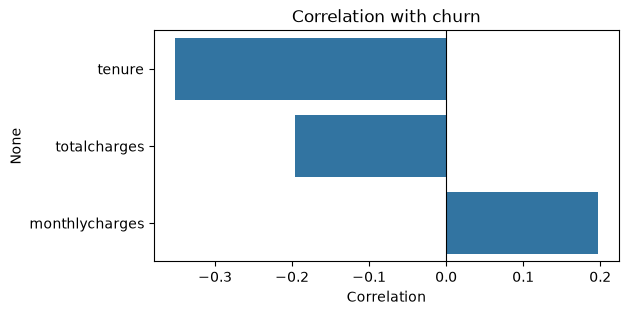

In [50]:
corr=df_full_train[numerical_var].corrwith(df_full_train.churn).sort_values()

plt.figure(figsize=(6, 3))
sns.barplot(x=corr.values, y=corr.index)
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Correlation with churn")
plt.xlabel("Correlation")
plt.show()

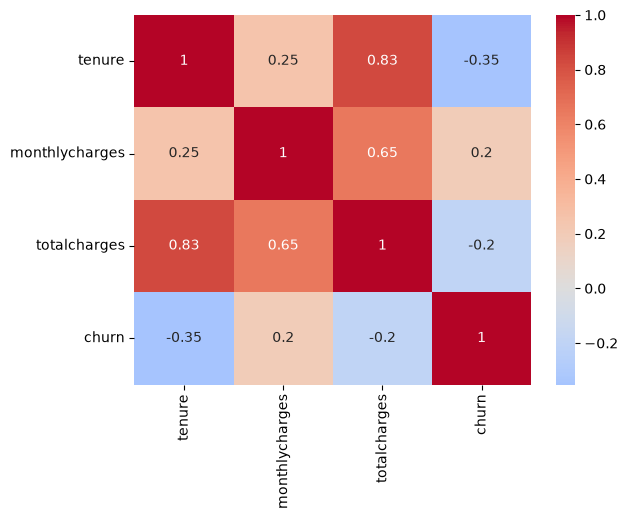

In [51]:
sns.heatmap(df_full_train[numerical_var + ["churn"]].corr(), annot=True, cmap="coolwarm", center=0)
plt.show()


One Hot Encoding

In [52]:
from sklearn.feature_extraction import DictVectorizer

In [53]:
train_dicts=df_train[categorical_var].to_dict(orient="records")

In [54]:
train_dicts[1]

{'gender': 'male',
 'seniorcitizen': 0,
 'partner': 'no',
 'dependents': 'no',
 'phoneservice': 'yes',
 'multiplelines': 'yes',
 'internetservice': 'fiber_optic',
 'onlinesecurity': 'no',
 'onlinebackup': 'yes',
 'deviceprotection': 'yes',
 'techsupport': 'no',
 'streamingtv': 'no',
 'streamingmovies': 'yes',
 'contract': 'month-to-month',
 'paperlessbilling': 'yes',
 'paymentmethod': 'electronic_check'}

In [55]:
dv=DictVectorizer(sparse=False)

In [56]:
X_train = dv.fit_transform(train_dicts)

In [57]:
X_train

array([[0., 0., 1., ..., 0., 0., 1.],
       [1., 0., 0., ..., 1., 0., 0.],
       [1., 0., 0., ..., 1., 0., 0.],
       ...,
       [1., 0., 0., ..., 0., 0., 1.],
       [0., 0., 1., ..., 0., 1., 0.],
       [1., 0., 0., ..., 1., 0., 0.]], shape=(4225, 42))

In [58]:
val_dicts=df_val[categorical_var].to_dict(orient="records")

In [73]:
x_val=dv.fit_transform(val_dicts)

In [74]:
x_val

array([[0., 0., 1., ..., 0., 0., 1.],
       [1., 0., 0., ..., 0., 1., 0.],
       [1., 0., 0., ..., 0., 1., 0.],
       ...,
       [1., 0., 0., ..., 0., 0., 1.],
       [1., 0., 0., ..., 1., 0., 0.],
       [1., 0., 0., ..., 1., 0., 0.]], shape=(1409, 42))

Logistic Regression

-  Binary Classification

- g(xi)= yi where G is the model, x is the feature matrix and y is the target variable.

In [61]:
def sigmoid(z):
    return 1/ (1+ np.exp(-z))

In [62]:
z=np.linspace(-9,9, 51)

In [63]:
sigmoid(z)

array([1.23394576e-04, 1.76855619e-04, 2.53472935e-04, 3.63270313e-04,
       5.20604074e-04, 7.46028834e-04, 1.06895950e-03, 1.53146171e-03,
       2.19363336e-03, 3.14121328e-03, 4.49627316e-03, 6.43210847e-03,
       9.19370537e-03, 1.31253183e-02, 1.87065100e-02, 2.65969936e-02,
       3.76878905e-02, 5.31511364e-02, 7.44679452e-02, 1.03400451e-01,
       1.41851065e-01, 1.91545349e-01, 2.53506017e-01, 3.27392983e-01,
       4.10959566e-01, 5.00000000e-01, 5.89040434e-01, 6.72607017e-01,
       7.46493983e-01, 8.08454651e-01, 8.58148935e-01, 8.96599549e-01,
       9.25532055e-01, 9.46848864e-01, 9.62312109e-01, 9.73403006e-01,
       9.81293490e-01, 9.86874682e-01, 9.90806295e-01, 9.93567892e-01,
       9.95503727e-01, 9.96858787e-01, 9.97806367e-01, 9.98468538e-01,
       9.98931040e-01, 9.99253971e-01, 9.99479396e-01, 9.99636730e-01,
       9.99746527e-01, 9.99823144e-01, 9.99876605e-01])

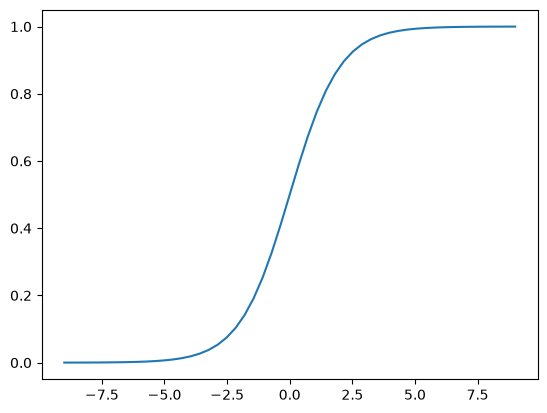

In [64]:
plt.plot(z, sigmoid(z))

In [65]:
def preparex(X):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])
    
    return X

In [66]:
def train_logistic_regression(X, y, lr=0.1, epochs=1000):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])

    w = np.zeros(X.shape[1])

    for _ in range(epochs):
        y_pred = sigmoid(X.dot(w))
        gradient = X.T.dot(y_pred - y) / len(y)
        w = w - lr * gradient

    return w[0], w[1:]

In [67]:
w0, w = train_logistic_regression(X_train, y_train)

In [68]:
w0, w

(np.float64(-0.2990838834027154),
 array([ 0.94694442, -0.31050023, -0.93552807, -0.11356972, -0.18551416,
         0.04117636, -0.1758707 , -0.16438955, -0.11474089, -0.18434299,
        -0.45107866,  0.32786548, -0.1758707 , -0.12561375, -0.03100249,
        -0.14246764,  0.09978937, -0.1758707 , -0.22300255,  0.23843864,
        -0.1758707 , -0.36165183, -0.3158137 ,  0.01672982, -0.08841044,
        -0.21067345, -0.28002969, -0.23337852,  0.13321684,  0.08110748,
        -0.03100249, -0.2680814 ,  0.09042992, -0.15847685, -0.1758707 ,
         0.03526367, -0.11752214, -0.1758707 , -0.00569104,  0.13861231,
        -0.1758707 , -0.26182549]))

In [72]:
x_val=preparex(x_val)

In [75]:
y_pred = sigmoid(w0+ x_val.dot(w)) 

In [ ]:
churn= y_pred>0.5

Train the logistic regression model with scikit-learn

In [76]:
from sklearn.linear_model import LogisticRegression

In [77]:
model=LogisticRegression()
model.fit(X_train,y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

In [78]:
model.intercept_[0]

np.float64(-0.32250660484056193)

In [79]:
model.predict(x_val) # harrd predictions 

array([0, 0, 0, ..., 0, 1, 1], shape=(1409,))

In [80]:
y_pred=model.predict_proba(x_val)[:, 1] #soft prediction

In [82]:
churn_decision= y_pred > 0.5 

In [83]:
churn_decision

array([False, False, False, ..., False,  True,  True], shape=(1409,))

In [90]:
(churn_decision == y_val).mean()

np.float64(0.8005677785663591)

In [86]:
df_val[churn_decision].customerid

8       3440-jpscl
12      7228-omtpn
19      6711-fldfb
24      2612-ranwt
30      3074-gqwyx
           ...    
1398    2034-cgrhz
1399    5276-kqwhg
1404    0980-pvmrc
1407    6521-yytyi
1408    3049-solay
Name: customerid, Length: 345, dtype: str

In [88]:
churn_decision.astype('int')

array([0, 0, 0, ..., 0, 1, 1], shape=(1409,))

In [91]:
df_pred= pd.DataFrame()
df_pred['probability']= y_pred
df_pred['prediction']=churn_decision
df_pred['actual_val']=y_val
df_pred['matching']=churn_decision == y_val

In [92]:
df_pred

,probability,prediction,actual_val,matching
0,0.018425,False,0,True
1,0.165793,False,0,True
2,0.175135,False,0,True
3,0.494661,False,1,False
4,0.136807,False,0,True
...,...,...,...,...
1404,0.506632,True,0,False
1405,0.096726,False,1,False
1406,0.188045,False,0,True
1407,0.688211,True,1,True


Model Interpretation

In [ ]:
small=['contract', 'tenure','monthlycharges']


In [101]:
x_train_dict=df_train[small].to_dict(orient="records")

In [105]:
dv=DictVectorizer(sparse=False)

In [107]:
x_train_small=dv.fit_transform(x_train_dict)

In [111]:
model=LogisticRegression()
model.fit(x_train_small,y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

In [114]:
model.intercept_[0]

np.float64(-2.477957595406315)

In [127]:
w=model.coef_[0]

In [130]:
x_train_small[0]

array([  0. ,   0. ,   1. , 115.5,  72. ])

In [128]:
dict(zip(dv.feature_names_ , w))

{'contract=month-to-month': np.float64(0.9711394012827222),
 'contract=one_year': np.float64(-0.023795073046539817),
 'contract=two_year': np.float64(-0.9482886283042673),
 'monthlycharges': np.float64(0.027485338780679085),
 'tenure': np.float64(-0.036190048291086026)}

In [132]:
sigmoid(-2.477957595406315 + (-0.9482886283042673) + 115.5*(0.027485338780679085)+ 12 * (-0.036190048291086026))

np.float64(0.3349301268509322)

In [138]:
x_val_small=df_val[small].values

In [143]:
x_val_small[50]

array(['month-to-month', 6, 48.95], dtype=object)

In [144]:
y_pred=sigmoid(-2.477957595406315+ (0.9711394012827222) + 48.95*(0.027485338780679085)+ 6 * (-0.036190048291086026)) 

In [145]:
y_pred

np.float64(0.4064763894071783)

In [146]:
y_val[50]

np.int64(0)

Using the model

In [157]:
x_full_train_dicts=df_full_train[categorical_var + numerical_var].to_dict(orient="records")

In [158]:
dv=DictVectorizer(sparse=False)
x_full_train=dv.fit_transform(x_full_train_dicts)

In [165]:
y_full_train=df_full_train.churn.values

In [166]:
y_full_train

array([0, 1, 0, ..., 1, 1, 0], shape=(5634,))

In [167]:
model=LogisticRegression()
model.fit(x_full_train,y_full_train)

d:\ML Zoomcamp\ML_zoo_2026\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

In [170]:
x_test_dict=df_test[categorical_var + numerical_var].to_dict(orient="records")

In [171]:
x_test=dv.transform(x_test_dict)

In [189]:
df_test.iloc[-1]

customerid                9874-qlclh
gender                        female
seniorcitizen                      0
partner                          yes
dependents                       yes
tenure                            17
phoneservice                     yes
multiplelines                    yes
internetservice          fiber_optic
onlinesecurity                   yes
onlinebackup                      no
deviceprotection                 yes
techsupport                       no
streamingtv                      yes
streamingmovies                  yes
contract              month-to-month
paperlessbilling                 yes
paymentmethod       electronic_check
monthlycharges                 104.2
totalcharges                  1743.5
Name: 1408, dtype: object

In [190]:
model.predict_proba(x_test[[-1]])[0,1]

np.float64(0.6239875684169238)

In [191]:
y_test[-1]

np.int64(1)